# Lab 2: a neural network (MLP) for handwritten digits

Lectures 2–4 · based on F. Chollet, M. Watson, *Deep Learning with Python*, 3rd ed., Chapter 2.

**How to work with this notebook**
* **Parts 1–3** are a complete worked example of the lectures. Run them cell by cell, read the comments and make sure you understand every line — Part 4 builds on this code.
* **Part 4** contains the **tasks (project)**: cells marked **TODO** are for you, plus short written answers in the cells *Your answer*.
  Some tasks are personalised: put your index number (*numer albumu*) into `STUDENT_ID` below.
* Runs on Google Colab (Runtime → Change runtime type; a GPU is optional, CPU is enough — one training takes ~15–30 s).

In [2]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"      # Part 3 uses tf.GradientTape

import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers, ops
import tensorflow as tf

STUDENT_ID = 222964          # <-- put your index number here (used for personalised tasks)
keras.utils.set_random_seed(0)
print("Keras", keras.__version__, "| backend:", keras.backend.backend())

Keras 3.16.0.dev2026111303 | backend: tensorflow


# Part 1. The first neural network (Lecture 2)

**Load the data.** 60 000 training and 10 000 test images, 28×28 pixels with values 0–255.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
(60000, 28, 28) uint8 [5 0 4 1 9 2 1 3 1 4]
(10000, 28, 28)


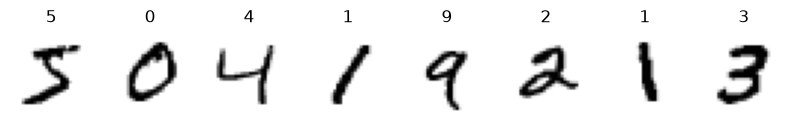

In [3]:
from keras.datasets import mnist
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

print(train_images.shape, train_images.dtype, train_labels[:10])
print(test_images.shape)

fig, axs = plt.subplots(1, 8, figsize=(10, 1.6))
for k, ax in enumerate(axs):
    ax.imshow(train_images[k], cmap="gray_r"); ax.set_title(train_labels[k]); ax.axis("off")
plt.show()

**Prepare the data.** Every image becomes a row of 784 numbers between 0 and 1.
We keep the original `train_images`, `test_images` (shape `(n, 28, 28)`) — Part 4 needs them.

In [4]:
x_train = train_images.reshape((60000, 28 * 28)).astype("float32") / 255
x_test = test_images.reshape((10000, 28 * 28)).astype("float32") / 255
print(x_train.shape, x_train.dtype, x_train.min(), x_train.max())

(60000, 784) float32 0.0 1.0


**The model:** a hidden `Dense` layer with 512 units and ReLU, and an output `Dense` layer with 10 units and softmax.
`model.summary()` shows the number of parameters: $784\cdot512+512 = 401\,920$ and $512\cdot10+10 = 5\,130$.

In [5]:
model = keras.Sequential([
    layers.Dense(512, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
model.build((None, 784))      # tell Keras the input size, so that summary() can count the weights
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 407,050 (1.55 MB)

 Trainable params: 407,050 (1.55 MB)

 Non-trainable params: 0 (0.00 B)

**Compile and train.** One epoch = 469 batches of 128 images.

In [6]:
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
history = model.fit(x_train, train_labels, epochs=5, batch_size=128, verbose=2)

Epoch 1/5
469/469 - 4s - 9ms/step - accuracy: 0.9238 - loss: 0.2677
Epoch 2/5
469/469 - 3s - 6ms/step - accuracy: 0.9685 - loss: 0.1083
Epoch 3/5
469/469 - 3s - 5ms/step - accuracy: 0.9800 - loss: 0.0700
Epoch 4/5
469/469 - 3s - 5ms/step - accuracy: 0.9865 - loss: 0.0490
Epoch 5/5
469/469 - 3s - 6ms/step - accuracy: 0.9912 - loss: 0.0347


In [7]:
test_loss, test_acc = model.evaluate(x_test, test_labels, verbose=0)
print(f"test accuracy: {test_acc:.4f}")

test accuracy: 0.9791


**Predictions.** `model.predict` returns a table of probabilities with shape `(n, 10)`;
the predicted digit is the index of the largest probability in each row (`np.argmax(..., axis=1)`).

In [8]:
probs = model.predict(x_test[:10], verbose=0)
print("probabilities for the first test image:", probs[0].round(3))
predicted = np.argmax(probs, axis=1)
print("predicted:", predicted)
print("true:     ", test_labels[:10])

probabilities for the first test image: [0.    0.    0.    0.004 0.    0.    0.    0.996 0.    0.   ]
predicted: [7 2 1 0 4 1 4 9 5 9]
true:      [7 2 1 0 4 1 4 9 5 9]


# Part 2. Tensors and tensor operations (Lectures 2–3)

**Slicing.** One index range per axis; `:` means "everything along this axis".

(14, 14) (60000, 14, 14)


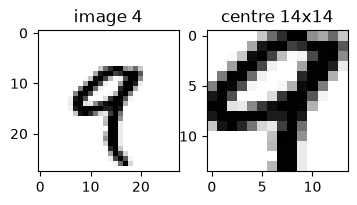

In [9]:
center = train_images[4, 7:-7, 7:-7]       # central 14x14 patch of image 4
corners = train_images[:, 14:, 14:]         # bottom-right 14x14 corner of all images
print(center.shape, corners.shape)

fig, axs = plt.subplots(1, 2, figsize=(4, 2))
axs[0].imshow(train_images[4], cmap="gray_r"); axs[0].set_title("image 4")
axs[1].imshow(center, cmap="gray_r"); axs[1].set_title("centre 14x14"); plt.show()

**Batches.** Axis 0 is the samples axis; batch number `n` (counting from 0) is a slice of 128 consecutive rows.

In [10]:
n, batch_size = 3, 128
batch = x_train[batch_size * n : batch_size * (n + 1)]
print(batch.shape, "- first row of the batch is image number", batch_size * n)

(128, 784) - first row of the batch is image number 384


**The network is just tensor operations.** We take the trained weights of the Keras model and compute its predictions **with NumPy only**:
$$h = \mathrm{relu}(x W_1 + b_1), \qquad s = h W_2 + b_2, \qquad p = \mathrm{softmax}(s).$$
Note the shapes: `(5, 784) @ (784, 512) -> (5, 512)`, and `+ b1` uses broadcasting (the same bias row is added to all 5 rows).

In [11]:
W1, b1 = model.layers[0].get_weights()
W2, b2 = model.layers[1].get_weights()
print("shapes:", W1.shape, b1.shape, W2.shape, b2.shape)

x = x_test[:5]                                          # a batch of 5 images, shape (5, 784)
h = np.maximum(x @ W1 + b1, 0)                          # hidden layer: matrix product, bias, ReLU
s = h @ W2 + b2                                         # scores of the 10 classes
p = np.exp(s) / np.exp(s).sum(axis=1, keepdims=True)    # softmax: every row sums to 1
print("shape of h:", h.shape, " shape of p:", p.shape)
print("same as Keras:", np.allclose(p, model.predict(x, verbose=0), atol=1e-4))

shapes: (784, 512) (512,) (512, 10) (10,)
shape of h: (5, 512)  shape of p: (5, 10)
same as Keras: True


Four lines of NumPy compute exactly what Keras computes. Training is "only" finding good values of `W1, b1, W2, b2`.

# Part 3. Gradients and a network from scratch (Lecture 4)

**3.1 The computation graph from the lecture.** `GradientTape` records the forward pass and computes the derivatives.
First the example from the slides ($y=4$), then the *Your turn* example ($y=10$) — compare with your answers from the lecture.

In [12]:
def tiny_model_gradients(x_, y_, w0=3.0, b0=1.0):
    w = tf.Variable(w0)
    b = tf.Variable(b0)
    with tf.GradientTape() as tape:
        x2 = w * x_ + b                 # prediction
        loss = tf.abs(y_ - x2)          # absolute error
    grad_w, grad_b = tape.gradient(loss, [w, b])
    return float(loss), float(grad_w), float(grad_b)

for y_ in [4.0, 10.0]:
    loss, gw, gb = tiny_model_gradients(2.0, y_)
    print(f"y = {y_:4}:  loss = {loss},  dL/dw = {gw},  dL/db = {gb}")

y =  4.0:  loss = 3.0,  dL/dw = 2.0,  dL/db = 1.0
y = 10.0:  loss = 3.0,  dL/dw = -2.0,  dL/db = -1.0


**3.2 A dense layer and a sequential model from scratch** (as on the slides).

In [13]:
class NaiveDense:
    def __init__(self, input_size, output_size, activation=None):
        self.activation = activation
        self.W = keras.Variable(shape=(input_size, output_size), initializer="uniform")
        self.b = keras.Variable(shape=(output_size,), initializer="zeros")

    def __call__(self, inputs):
        x = ops.matmul(inputs, self.W) + self.b      # inputs @ W + b
        if self.activation is not None:
            x = self.activation(x)
        return x

    @property
    def weights(self):
        return [self.W, self.b]


class NaiveSequential:
    def __init__(self, layers):
        self.layers = layers

    def __call__(self, inputs):
        x = inputs
        for layer in self.layers:
            x = layer(x)
        return x

    @property
    def weights(self):
        weights = []
        for layer in self.layers:
            weights += layer.weights
        return weights

**3.3 Training: one step of gradient descent and the training loop.**
`update_weights` uses the global variable `learning_rate` (you will change it in Task 4).

In [14]:
learning_rate = 1e-3

def update_weights(gradients, weights):
    for g, w in zip(gradients, weights):
        w.assign(w - g * learning_rate)              # gradient-descent step

def one_training_step(model, images_batch, labels_batch):
    with tf.GradientTape() as tape:
        predictions = model(images_batch)                                   # forward pass
        losses = ops.sparse_categorical_crossentropy(labels_batch, predictions)
        average_loss = ops.mean(losses)
    gradients = tape.gradient(average_loss, model.weights)                  # backward pass
    update_weights(gradients, model.weights)
    return float(average_loss)

def fit(model, images, labels, epochs, batch_size=128):
    epoch_losses = []
    for epoch in range(epochs):
        batch_losses = []
        for start in range(0, len(images), batch_size):
            batch_losses.append(one_training_step(model, images[start:start + batch_size],
                                                  labels[start:start + batch_size]))
        epoch_losses.append(np.mean(batch_losses))
        print(f"epoch {epoch}: mean loss {epoch_losses[-1]:.3f}")
    return epoch_losses

In [15]:
keras.utils.set_random_seed(0)
scratch_model = NaiveSequential([NaiveDense(784, 512, ops.relu), NaiveDense(512, 10, ops.softmax)])
scratch_losses = fit(scratch_model, x_train, train_labels, epochs=10)

epoch 0: mean loss 2.224
epoch 1: mean loss 2.062
epoch 2: mean loss 1.890
epoch 3: mean loss 1.708
epoch 4: mean loss 1.526
epoch 5: mean loss 1.356
epoch 6: mean loss 1.208
epoch 7: mean loss 1.085
epoch 8: mean loss 0.985
epoch 9: mean loss 0.903


**Accuracy on the test set:** the fraction of test images whose predicted digit (argmax) equals the true label.

In [16]:
test_probs = ops.convert_to_numpy(scratch_model(x_test))
scratch_acc = (np.argmax(test_probs, axis=1) == test_labels).mean()
print(f"scratch model (plain SGD, lr=1e-3, 10 epochs): test accuracy {scratch_acc:.3f}")
print(f"Keras model   (Adam, 5 epochs):                test accuracy {test_acc:.3f}")

scratch model (plain SGD, lr=1e-3, 10 epochs): test accuracy 0.837
Keras model   (Adam, 5 epochs):                test accuracy 0.979


# Part 4. Tasks (project)

For each task: write the code in the **TODO** cell (you can reuse anything from Parts 1–3), show the results (a table or a plot),
and answer the questions in the *Your answer* cell in your own words (2–5 sentences per question).
Tasks 1–4 are compulsory, tasks 5–6 are optional (extra points).

The helper below trains the same MLP as in Part 1 on any images and returns the trained model and the test accuracy.

In [17]:
def to_inputs(images):
    """(n, h, w) uint8 images  ->  (n, h*w) float32 in [0, 1]"""
    return images.reshape(len(images), -1).astype("float32") / 255

def train_mlp(train_imgs, train_lbls, test_imgs, test_lbls, epochs=5, seed=0,
              hidden=512, activation="relu", verbose=0):
    keras.utils.set_random_seed(seed)
    model = keras.Sequential([layers.Dense(hidden, activation=activation),
                              layers.Dense(10, activation="softmax")])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    model.fit(to_inputs(train_imgs), train_lbls, epochs=epochs, batch_size=128, verbose=verbose)
    acc = model.evaluate(to_inputs(test_imgs), test_lbls, verbose=0)[1]
    return model, acc

rng = np.random.default_rng(STUDENT_ID)     # personalised random numbers

## Task 1. Shuffling the pixels

Choose **one fixed random permutation** of the 784 pixel positions and apply it to **all** images (training and test): pixel 0 goes to position `perm[0]`, and so on.

1. Show 5 permuted training images. Can you still recognise the digits?
2. Train the MLP on the permuted images and evaluate it on the permuted test images. Repeat for 3 seeds (`seed=0, 1, 2`) and compare with the original images (also 3 seeds). Report mean and standard deviation.
3. Evaluate the model trained on permuted images on test images permuted with a **different** permutation.

**Questions.** (a) Why does the MLP not care about the permutation? *Hint:* does a `Dense` layer know which pixels are neighbours?
(b) What happens in point 3, and why? (c) We will repeat this experiment with a convolutional network (CNN). What do you expect?

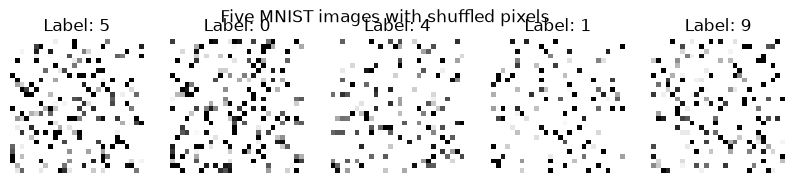

In [18]:
perm = rng.permutation(784)
train_perm = train_images.reshape(60000, 784)[:, perm].reshape(60000, 28, 28)
test_perm = test_images.reshape(10000, 784)[:, perm].reshape(10000, 28, 28)

# TODO: 1. show 5 permuted images;  2. 3 seeds original vs permuted;  3. a different permutation for the test set
# 1.
fig, axs = plt.subplots(1, 5, figsize=(10, 2))

for i, ax in enumerate(axs):
    ax.imshow(train_perm[i], cmap="gray_r")
    ax.set_title(f"Label: {train_labels[i]}")
    ax.axis("off")

plt.suptitle("Five MNIST images with shuffled pixels")
plt.tight_layout
plt.show()

In [19]:
# 2.
original_accuracies = []
permuted_accuracies = []

for seed in [0, 1, 2]:
    print(f"Seed: {seed}")

    #orig img
    _, acc_original = train_mlp(
        train_images, train_labels,
        test_images, test_labels,
        epochs=5, seed=seed
    )
    original_accuracies.append(acc_original)

    #permtd img
    _, acc_permuted = train_mlp(
        train_perm, train_labels,
        test_perm, test_labels,
        epochs=5, seed=seed
    )
    permuted_accuracies.append(acc_permuted)

print("\n Original images:")
print("Accuracies:", original_accuracies)
print(f"Mean: {np.mean(original_accuracies):.4f}")
print(f"Std: {np.std(original_accuracies):.4f}")

Seed: 0
Seed: 1
Seed: 2

 Original images:
Accuracies: [0.9790999889373779, 0.977400004863739, 0.9781000018119812]
Mean: 0.9782
Std: 0.0007


In [22]:
# 3.
different_perm = rng.permutation(784)

test_different_perm = (
    test_images.reshape(10000, 784)[:, different_perm].reshape(10000, 28, 28)
)

permuted_model, _ = train_mlp(
    train_perm, train_labels,
    test_perm, test_labels,
    epochs=5, seed=0
)

different_perm_acc = permuted_model.evaluate(
    to_inputs(test_different_perm),
    test_labels,
    verbose=0
)[1]

print(
    f"Accuracy on a different permutation: "
    f"{different_perm_acc:.4f}"
)

Accuracy on a different permutation: 0.1072


**Your answer (Task 1):**

(a) Warstwa `Dense` traktuje każdy piksel osobno, nie zwraca uwagi na jego sąsiedztwo, więc model rozpoznaje cyfry mimo przetasowania pikseli jeśli ich kolejność jest taka sama podczas trenowania i testowania

(b) Dokładność spadła do 14,25%, bo model nauczył się układów pikseli które po przetasowaniu się zmieniają

(c) CNN prawdopodobnie osiągnie gorszy wynik, bo weźmie pod uwagę sąsiedztwo pikseli i wzory 

## Task 2. Borders and crops

MNIST digits were normalised to fit a 20×20 box and centred in the 28×28 image, so the border is almost empty.

1. For border widths $k = 1, 2, 3, 4$ compute: the fraction of images that have **any** non-zero pixel in the border, and the fraction of all "ink" (sum of pixel values) that lies in the border.
2. Remove a border of width $k=2$ and $k=3$ (slicing!), train the MLP on the smaller images and compare accuracy and **number of parameters** with the 28×28 model.
3. **Random crops.** Create 24×24 crops: (i) the *centre* crop and (ii) a *random* crop for every image (a random offset 0–4 in each direction; use `random_crops`).
   Train one model on centre crops and one on random crops. Evaluate both on centre crops and on random crops of the test set (a 2×2 table).

**Questions.** (a) Why does removing the border change (almost) nothing? What do we gain? (b) Explain the 2×2 table. What does it say about how the MLP "sees" images?
(c) Training on random crops is a simple form of **data augmentation**. Why does it help on shifted test images? What does it cost?

In [23]:
def random_crops(images, size, rng):
    """One random size x size crop of every image."""
    n, H, W = images.shape
    oi = rng.integers(0, H - size + 1, n)
    oj = rng.integers(0, W - size + 1, n)
    return np.stack([img[i:i + size, j:j + size] for img, i, j in zip(images, oi, oj)])

# TODO: 1. border statistics;  2. remove borders k=2,3;  3. the 2x2 table
# 1.
print("Border statistics:")

for k in [1, 2, 3, 4]:
    border_mask = np.ones((28, 28), dtype=bool)
    border_mask[k:28-k, k:28-k] = False

    border_pixels = train_images[:, border_mask]

    fraction_images = np.mean(np.any(border_pixels > 0, axis=1))
    fraction_ink = border_pixels.sum() / train_images.sum()

    print(
        f"k={k}: images with non-zero border = {fraction_images:.4f}, "
        f"fraction of ink in border = {fraction_ink:.4f}"
    )

Border statistics:
k=1: images with non-zero border = 0.0135, fraction of ink in border = 0.0002
k=2: images with non-zero border = 0.1205, fraction of ink in border = 0.0024
k=3: images with non-zero border = 0.3545, fraction of ink in border = 0.0100
k=4: images with non-zero border = 0.7562, fraction of ink in border = 0.0334


In [24]:
# 2.
print("Models with removed borders:")

original_params = model.count_params()
print(f"Original 28x28 model: {original_params} parameters")

for k in [2, 3]:
    train_crop = train_images[:, k:28-k, k:28-k]
    test_crop = test_images[:, k:28-k, k:28-k]

    crop_model, crop_acc = train_mlp(
        train_crop, train_labels,
        test_crop, test_labels,
        epochs=5, seed=0
    )

    print(
        f"k={k}, image size={28-2*k}x{28-2*k}, "
        f"parameters={crop_model.count_params()}, "
        f"accuracy={crop_acc:.4f}"
    )

Models with removed borders:
Original 28x28 model: 407050 parameters
k=2, image size=24x24, parameters=300554, accuracy=0.9774
k=3, image size=22x22, parameters=253450, accuracy=0.9783


In [25]:
# 3.
train_center = train_images[:, 2:26, 2:26]
test_center = test_images[:, 2:26, 2:26]

train_random = random_crops(train_images, 24, rng)
test_random = random_crops(test_images, 24, rng)

center_model, center_acc = train_mlp(
    train_center, train_labels,
    test_center, test_labels,
    epochs=5, seed=0
)

random_model, random_acc = train_mlp(
    train_random, train_labels,
    test_random, test_labels,
    epochs=5, seed=0
)

center_on_center = center_model.evaluate(to_inputs(test_center), test_labels, verbose=0)[1]
center_on_random = center_model.evaluate(to_inputs(test_random), test_labels, verbose=0)[1]
random_on_center = random_model.evaluate(to_inputs(test_center), test_labels, verbose=0)[1]
random_on_random = random_model.evaluate(to_inputs(test_random), test_labels, verbose=0)[1]

print("2x2 comparison table:")
print(f"{'Training data':<20} {'Centre test':>12} {'Random test':>12}")
print("-" * 46)
print(f"{'Centre crops':<20} {center_on_center:>12.4f} {center_on_random:>12.4f}")
print(f"{'Random crops':<20} {random_on_center:>12.4f} {random_on_random:>12.4f}")

2x2 comparison table:
Training data         Centre test  Random test
----------------------------------------------
Centre crops               0.9774       0.8083
Random crops               0.9743       0.9664


**Questions.** (a) Why does removing the border change (almost) nothing? What do we gain? (b) Explain the 2×2 table. What does it say about how the MLP "sees" images?
(c) Training on random crops is a simple form of **data augmentation**. Why does it help on shifted test images? What does it cost?

**Your answer (Task 2):**

(a) Ponieważ większość informacji o cyfrach znajduje się na środku obrazka więc prawie nic nie tracimy. Dzięki temu zmniejszamy rozmiar obrazka i liczbę parametrów sieci.

(b) Model wytrenowany na wycentrowanych obrazkach gorzej rozpoznaje losowo przycięte obrazki, natomiast model trenowany na losowo przyciętych obrazkach radzi sobie dobrze w obu przypadkach. MLP jest wrażliwy na położenie pikseli i przesunicia obrazu.

(c) Zwiększa to różnorodność danych treningowych przez co model uczy się rozpoznawać cyfry w różnych położeniach, co poprawia jego skuteczność, ale wymaga dodatkowego przygotowania danych i treningu.

## Task 3. Is the activation function necessary?

Train the same network **without** ReLU (`activation=None`) and a plain linear classifier `keras.Sequential([layers.Dense(10, activation="softmax")])`.
Compare test accuracies and numbers of parameters with the original MLP.

**Questions.** (a) Using the slide *"Why do we need an activation between layers?"*, explain the result. (b) Is the model without ReLU better than the plain linear classifier? Why (not)?

In [ ]:
# TODO: train the MLP without activation and the linear classifier, compare accuracy and parameters
...

**Your answer (Task 3):**

(a) ...

(b) ...

## Task 4. The learning rate (scratch model)

Train the scratch model from Part 3 for 3 epochs with learning rates `1e-3, 1e-2, 1e-1, 1.0, 3.0`. Plot the mean loss per epoch for all of them in one figure and report the test accuracy.
*Hint:* `update_weights` uses the global variable `learning_rate` — change it before each run, and create a **new** model each time.

**Questions.** (a) Which learning rate works best? What goes wrong with the smallest and with the largest? Relate to the lecture figure with $\eta$ = too small / good / oscillates / diverges.
(b) Why does the Keras model with Adam reach ≈98% after 5 epochs, while the scratch model with `1e-3` is far behind?

In [ ]:
# TODO: loop over learning rates: new model, fit for 3 epochs, store losses and test accuracy; plot
...

**Your answer (Task 4):**

(a) ...

(b) ...

## Task 5 (optional). How much data do we need?

Train the MLP on the first $n$ training images for $n = 500, 2000, 10000, 60000$ (use `epochs=20` for $n \le 2000$, otherwise 5).
For each $n$ report the **training** and the **test** accuracy and plot both against $n$ (log scale).

**Question.** How does the gap between training and test accuracy change with $n$? What is this phenomenon called?

In [ ]:
# TODO: train on subsets, compute train and test accuracy, plot
...

**Your answer (Task 5):** ...

## Task 6 (optional). Noisy images

Add Gaussian noise with standard deviation $\sigma \in \{0, 0.1, 0.2, 0.3, 0.5\}$ to the **test** inputs `x_test` (then clip to [0, 1]) and plot the accuracy of the model from Part 1 against $\sigma$.
Then train a model on noisy training images ($\sigma = 0.3$, noise added once) and add its curve to the plot.

**Question.** What does training on noisy images change? Compare with Task 2(c).

In [ ]:
# TODO: accuracy vs noise level for the original model and for a model trained on noisy images
...

**Your answer (Task 6):** ...

---
**Submission (project).** Hand in this notebook with all TODOs completed, all tasks run (outputs visible), and the *Your answer* cells filled in.